# 01 Revisión práctica de Machine Learning

## Propósito

Repasar los fundamentos de Machine Learning. Compararemos métodos sobre los mismos datasets y explicaremos sus resultados.

Esta práctica corresponde a una revisión de contenidos previos de Machine Learning. No requiere conocimientos de Recuperación de Información.

## Objetivos

Al completar el notebook podrás:

- Distinguir clasificación, regresión, clustering, recomendación y asociación.
- Preparar datos y separar entrenamiento, validación y prueba.
- Comparar modelos mediante métricas apropiadas.
- Explicar los efectos del escalamiento, los hiperparámetros y la regularización.
- Interpretar softmax y las salidas de un MLP.
- Identificar limitaciones y errores de los modelos.

## Uso de IA Generativa

Puedes usar IA para generar, corregir y explicar código. Debes comprobar que el código corresponde al experimento solicitado y poder explicar las decisiones y los resultados.

Antes de solicitar una implementación, registra tu predicción sobre el experimento.

## Organización del trabajo

Después de cada bloque de instrucciones, añade las celdas de código y Markdown necesarias.

Cada experimento debe incluir:

1. Una predicción inicial.
2. La implementación y sus resultados.
3. Una interpretación basada en los conceptos de ML.
4. Una respuesta a las preguntas planteadas.

Las tablas y figuras deben generarse a partir de los resultados obtenidos.

# 1. Datos y protocolo experimental

## Dataset inicial: Iris

Carga el dataset Iris, incluido en scikit-learn.

Identifica:

- Qué representa cada instancia.
- Número de instancias y características.
- Nombre y significado de cada característica.
- Clases y cantidad de ejemplos por clase.
- Dimensiones de la matriz de características y del vector de etiquetas.

Presenta una tabla con cinco ejemplos y un gráfico de distribución de clases.


**Descripción de Iris:** Cada instancia representa una flor. Hay 150 ejemplos con cuatro características medidas en centímetros: largo y ancho del sépalo, y largo y ancho del pétalo. Las clases son setosa, versicolor y virginica, con 50 flores en cada una. Por eso X tiene dimensiones (150, 4) y el vector de etiquetas tiene 150 valores.


In [1]:
# Cargar el dataset Iris

from sklearn.datasets import load_iris
import pandas as pd

iris = load_iris()

print(iris.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [2]:
# Número de instancias y características

print("Número de instancias:", iris.data.shape[0])
print("Número de características:", iris.data.shape[1])

# Nombre de las características

print("Características:")
for feature in iris.feature_names:
    print("-", feature)

# Nombre de las clases
print("\nClases:", iris.target_names)



Número de instancias: 150
Número de características: 4
Características:
- sepal length (cm)
- sepal width (cm)
- petal length (cm)
- petal width (cm)

Clases: ['setosa' 'versicolor' 'virginica']


In [3]:
# Comprobar las dimensiones

# Matriz de características
X = iris.data

# Vector de etiquetas
Y = iris.target

print("Dimensiones de X:", X.shape)
print("Dimensiones de Y:", Y.shape)



Dimensiones de X: (150, 4)
Dimensiones de Y: (150,)


In [4]:
# Identificar las clases y cantidad de ejemplos por clase

import numpy as np

# Contamos cuántas flores pertenecen a cada clase
clases, cantidades = np.unique(Y, return_counts=True)

for clase, cantidad in zip(clases, cantidades):
    print(iris.target_names[clase], ":", cantidad)

setosa : 50
versicolor : 50
virginica : 50


In [5]:
# Creamos una tabla con las características
df = pd.DataFrame(X, columns=iris.feature_names)

# Agregamos la columna con el nombre de la especie
df["especie"] = iris.target_names[Y]

# Mostramos los primeros cinco ejemplos
display(df.head(5))

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),especie
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Text(0, 0.5, 'Cantidad de flores')

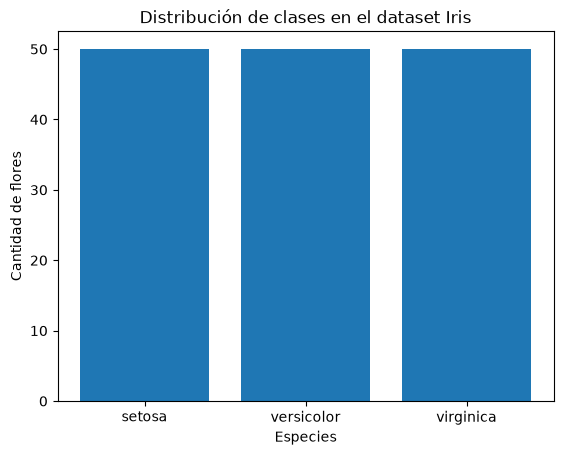

In [6]:
# Gráfico de distribución de clases
import matplotlib.pyplot as plt

plt.bar(iris.target_names, cantidades)

plt.title("Distribución de clases en el dataset Iris")
plt.xlabel("Especies")
plt.ylabel("Cantidad de flores")



# 2. Comparación de clasificadores



## Predicciones iniciales

Antes de implementar, responde:

1. ¿Qué modelos crees que serán sensibles a las escalas de las características?

Creo que los modelos especialmente sensibles a la escala son la regresión logística, SVM y MLP, aunque los árboles de decisión y sus conjuntos suelen ser mucho menos sensibles.

2. ¿Qué modelo esperas que produzca fronteras de decisión más simples?

Espero que sean la regresión logística y SVM lineal, ya que producen fronteras de decisión lineales.

3. ¿Por qué no podemos asegurar de antemano cuál será el mejor?

Porque cada modelo aprende de manera distinta y su desempeño depende de la distribución de los datos, sus parámetros y su capacidad de generalizar a ejemplos que nunca ha visto.

## Modelos

Construye un modelo de clasificación para la clase y compara:

- Gaussian Naive Bayes.
- Regresión logística multiclase.
- SVM lineal.
- Árbol de decisión.
- Random Forest.
- Gradient Boosting.
- MLP de clasificación.

Usa características estandarizadas para los clasificadores.

## Procedimiento

1. Define configuraciones iniciales.
2. Entrena con la partición de entrenamiento.
3. Compara accuracy y F1 macro en validación.
4. Realiza ajustes limitados usando solamente validación.
5. Congela las configuraciones.
6. Evalúa todos los modelos finales sobre la misma partición de prueba.

La tabla de prueba describe sus resultados; no debe iniciar una nueva ronda de ajuste.

## Resultados

Presenta una tabla con:

| Modelo | Transformación | Hiperparámetros principales | Accuracy de prueba | F1 macro de prueba |
|---|---|---|---|---|

Incluye matrices de confusión de Naive Bayes, SVM y MLP.

## Interpretación

1. ¿Cuál fue el modelo con el mejor desempeño?
2. ¿Cuál fue el modelo más sencillo de programar?
3. ¿Accuracy y F1 macro cuentan la misma historia?
4. ¿Cuál es la diferencia entre las métricas macro y micro?
5. ¿Qué aporta el MLP frente a un modelo lineal?

Selecciona dos errores de clasificación. Examina sus características y explica qué puedes concluir y qué no puedes concluir sobre la causa del error.

In [7]:
from sklearn.model_selection import train_test_split

# Primera división: 60% para entrenamiento y 40% temporal
X_train, X_temp, Y_train, y_temp = train_test_split(
    X, Y, test_size=0.4, random_state=42, stratify=Y)

# Segunda división: 20% validación y 20% prueba
X_val, X_test, Y_val, Y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)


print("Entrenamiento", X_train.shape)
print("Validación", X_val.shape)
print("Prueba", X_test.shape)

Entrenamiento (90, 4)
Validación (30, 4)
Prueba (30, 4)


In [8]:
# Comprobar la distribución por clase

print("Clases en entrenamiento:",
      np.bincount(Y_train))

print("Clases en validación:",
      np.bincount(Y_val))

print("Clases en prueba:",
      np.bincount(Y_test))

Clases en entrenamiento: [30 30 30]
Clases en validación: [10 10 10]
Clases en prueba: [10 10 10]


In [9]:
# Estandarizar las características

from sklearn.preprocessing import StandardScaler

# Creamos el estandarizador

scaler = StandardScaler()

# Aprende la media y desviación del entrenamiento
X_train_scaled = scaler.fit_transform(X_train)

# Aplicar la misma transformación
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Antes de estandarizar:")
print(X_train[0])

print("\nDespués de estandarizar:")
print(X_train_scaled[0])

Antes de estandarizar:
[7.4 2.8 6.1 1.9]

Después de estandarizar:
[ 1.78875477 -0.56542435  1.30146023  0.90537292]


In [10]:
from sklearn.naive_bayes import GaussianNB

# Creamos el clasificador
modelo_nb = GaussianNB()

# Entrenamos con los datos de entrenamiento
modelo_nb.fit(X_train_scaled, Y_train)

# Realizamos predicciones con validación
y_pred_np = modelo_nb.predict(X_val_scaled)

print("Predicciones:", y_pred_np)
print("Valores reales:", Y_val)

Predicciones: [2 0 2 1 1 1 2 0 2 0 0 2 1 2 1 2 1 2 1 0 0 0 2 0 1 0 1 2 0 1]
Valores reales: [2 0 2 1 1 1 2 0 2 0 0 2 1 2 1 2 1 2 2 0 0 0 2 0 1 0 1 1 0 1]


In [11]:
# Evaluamos el modelo
from sklearn.metrics import accuracy_score, f1_score

accuracy_nb = accuracy_score(Y_val, y_pred_np)
f1_nb = f1_score(Y_val, y_pred_np, average = "macro")

print("Accuracy:", round(accuracy_nb, 4))
print("F1 macro:", round(f1_nb, 4))

Accuracy: 0.9333
F1 macro: 0.9333


### Regresión logística

In [12]:
from sklearn.linear_model import LogisticRegression

# Creamos el clasificador de regresión logística
modelo_lr = LogisticRegression(max_iter=1000)

# Entrenamos con los datos de entrenamiento
modelo_lr.fit(X_train_scaled, Y_train)

# Realizamos predicciones con validación
y_pred_lr = modelo_lr.predict(X_val_scaled)

print("Predicciones:", y_pred_lr)
print("Valores reales:", Y_val)

Predicciones: [2 0 2 1 1 1 2 0 2 0 0 2 1 2 1 2 1 2 1 0 0 0 2 0 1 0 1 2 0 1]
Valores reales: [2 0 2 1 1 1 2 0 2 0 0 2 1 2 1 2 1 2 2 0 0 0 2 0 1 0 1 1 0 1]


In [13]:
# Evaluar la regresion logistica
accuracy_lr = accuracy_score(Y_val, y_pred_lr)
f1_lr = f1_score(Y_val, y_pred_lr, average = "macro")

print("Accuracy:", round(accuracy_lr, 4))
print("F1 macro:", round(f1_lr, 4))

Accuracy: 0.9333
F1 macro: 0.9333


### Entrenar SVM lineal

In [14]:
from sklearn.svm import SVC

# Creamos el clasificador SVM

modelo_svm = SVC(kernel="linear")

# Entrenamos el modelo

modelo_svm.fit(X_train_scaled, Y_train)

# Predecimos las flores con validación

y_pred_svm = modelo_svm.predict(X_val_scaled)

print("Predicciones:", y_pred_svm)
print("Vaores reales:", Y_val)

Predicciones: [2 0 2 1 1 1 2 0 2 0 0 2 1 2 1 2 1 2 2 0 0 0 2 0 1 0 1 2 0 1]
Vaores reales: [2 0 2 1 1 1 2 0 2 0 0 2 1 2 1 2 1 2 2 0 0 0 2 0 1 0 1 1 0 1]


In [15]:
# Evaluar el modelo
accuracy_svm = accuracy_score(Y_val, y_pred_svm)
f1_svm = f1_score(Y_val, y_pred_svm, average = "macro")

print("Accuracy:", round(accuracy_svm, 4))
print("F1 macro:", round(f1_svm, 4))

Accuracy: 0.9667
F1 macro: 0.9666


### Entrenar el arbol

In [16]:
from sklearn.tree import DecisionTreeClassifier

# Creamos el modelo
modelo_dt = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

# Entrenamos el modelo
modelo_dt.fit(X_train_scaled, Y_train)

# Realizamos las predicciones
y_pred_dt = modelo_dt.predict(X_val_scaled)

print("Predicciones:", y_pred_dt)
print("Valores reales:", Y_val)

Predicciones: [2 0 2 1 1 1 2 0 2 0 0 2 1 2 1 2 1 2 2 0 0 0 2 0 1 0 1 2 0 1]
Valores reales: [2 0 2 1 1 1 2 0 2 0 0 2 1 2 1 2 1 2 2 0 0 0 2 0 1 0 1 1 0 1]


In [17]:
# Evaluar el modelo
accuracy_dt = accuracy_score(Y_val, y_pred_dt)
f1_dt = f1_score(Y_val, y_pred_dt, average = "macro")

print("Accuracy:", round(accuracy_dt, 4))
print("F1 macro:", round(f1_dt, 4))

Accuracy: 0.9667
F1 macro: 0.9666


### Random Forest

In [18]:
from sklearn.ensemble import RandomForestClassifier

# Creamos el modelo
modelo_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Entrenamos el modelo
modelo_rf.fit(X_train_scaled, Y_train)

# Realizamos las predicciones
y_pred_rf = modelo_rf.predict(X_val_scaled)

print("Predicciones:", y_pred_rf)
print("Valores reales:", Y_val)

Predicciones: [2 0 2 1 1 1 2 0 2 0 0 2 1 2 1 2 1 2 1 0 0 0 2 0 1 0 1 2 0 1]
Valores reales: [2 0 2 1 1 1 2 0 2 0 0 2 1 2 1 2 1 2 2 0 0 0 2 0 1 0 1 1 0 1]


In [19]:
# Evaluamos el modelo
accuracy_rf = accuracy_score(Y_val, y_pred_rf)
f1_rf = f1_score(Y_val, y_pred_rf, average = "macro")

print("Accuracy:", round(accuracy_rf, 4))
print("F1 macro:", round(f1_rf, 4))

Accuracy: 0.9333
F1 macro: 0.9333


### Gradient Boosting

In [20]:
from sklearn.ensemble import GradientBoostingClassifier

# Creamos el modelo
modelo_gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Entrenamos el modelo
modelo_gb.fit(X_train_scaled, Y_train)

# predecimos
y_pred_gb = modelo_gb.predict(X_val_scaled)

print("Predicciones:", y_pred_gb)
print("Valores reales:", Y_val)

Predicciones: [1 0 2 1 1 1 2 0 2 0 0 2 1 2 1 2 1 2 2 0 0 0 2 0 1 0 1 2 0 1]
Valores reales: [2 0 2 1 1 1 2 0 2 0 0 2 1 2 1 2 1 2 2 0 0 0 2 0 1 0 1 1 0 1]


In [21]:
# Evaluamos el modelo
accuracy_gb = accuracy_score(Y_val, y_pred_gb)
f1_gb = f1_score(Y_val, y_pred_gb, average = "macro")

print("Accuracy:", round(accuracy_gb, 4))
print("F1 macro:", round(f1_gb, 4))

Accuracy: 0.9333
F1 macro: 0.9333


### Entrenar MLP

In [22]:
from sklearn.neural_network import MLPClassifier

# Creamos el modelo
modelo_mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    max_iter=2000,
    random_state=42
)

# Entrenamos el modelo
modelo_mlp.fit(X_train_scaled, Y_train)

# Realizamos las predicciones
y_pred_mlp = modelo_mlp.predict(X_val_scaled)

print("Predicciones:", y_pred_mlp)
print("Valores reales:", Y_val)


Predicciones: [2 0 2 1 1 1 2 0 2 0 0 2 1 2 1 2 1 2 2 0 0 0 2 0 1 0 1 2 0 1]
Valores reales: [2 0 2 1 1 1 2 0 2 0 0 2 1 2 1 2 1 2 2 0 0 0 2 0 1 0 1 1 0 1]


In [23]:
# Evaluamos el modelo
accuracy_mlp = accuracy_score(Y_val, y_pred_mlp)
f1_mlp = f1_score(Y_val, y_pred_mlp, average = "macro")

print("Accuracy:", round(accuracy_mlp, 4))
print("F1 macro:", round(f1_mlp, 4))

Accuracy: 0.9667
F1 macro: 0.9666


### Comparar los modelos

In [24]:

import pandas as pd

resultados = pd.DataFrame({
    "Modelo": [
        "Gaussian Naive Bayes",
        "Regresión logística",
        "Support Vector Machine",
        "Arbol de decisión",
        "Random Forest",
        "Gradient Boosting",
        "MLP"
    ],
    "Accuracy validación": [
        accuracy_nb,
        accuracy_lr,
        accuracy_svm,
        accuracy_dt,
        accuracy_rf,
        accuracy_gb,
        accuracy_mlp
    ],
    "F1 macro validación": [
        f1_nb,
        f1_lr,
        f1_svm,
        f1_dt,
        f1_rf,
        f1_gb,
        f1_mlp
    ]
})

display(resultados.round(4))


,Modelo,Accuracy validación,F1 macro validación
0,Gaussian Naive Bayes,0.9333,0.9333
1,Regresión logística,0.9333,0.9333
2,Support Vector Machine,0.9667,0.9666
3,Arbol de decisión,0.9667,0.9666
4,Random Forest,0.9333,0.9333
5,Gradient Boosting,0.9333,0.9333
6,MLP,0.9667,0.9666


### Ajuste limitado de hiperparámetros

Se compararon varias configuraciones usando **solo el conjunto de validación**, antes de evaluar los modelos en prueba. Se probaron `C = [0.1, 1, 10]` en SVM, `max_depth = [2, 3, 5]` en el árbol de decisión y las arquitecturas `(16,)`, `(32, 16)` y `(64, 32)` en MLP. Las configuraciones que se conservaron fueron `C=1.0`, `max_depth=3` y `hidden_layer_sizes=(64, 32)`.

El siguiente código permite reproducir las comparaciones realizadas con validación, sin modificar los modelos finales ni consultar los datos de prueba.

In [25]:
# Comprobar los ajustes usando solamente validación
opciones = {
    "SVM (C)": [(c, SVC(kernel="linear", C=c)) for c in [0.1, 1, 10]],
    "Árbol (profundidad)": [
        (d, DecisionTreeClassifier(max_depth=d, random_state=42))
        for d in [2, 3, 5]
    ],
    "MLP (arquitectura)": [
        (a, MLPClassifier(hidden_layer_sizes=a, activation="relu",
                          max_iter=2000, random_state=42))
        for a in [(16,), (32, 16), (64, 32)]
    ]
}

for nombre, candidatos in opciones.items():
    filas_ajuste = []
    for parametro, modelo_candidato in candidatos:
        modelo_candidato.fit(X_train_scaled, Y_train)
        pred = modelo_candidato.predict(X_val_scaled)
        filas_ajuste.append({
            "Configuración": str(parametro),
            "Accuracy": accuracy_score(Y_val, pred),
            "F1 macro": f1_score(Y_val, pred, average="macro")
        })
    print("\n", nombre)
    display(pd.DataFrame(filas_ajuste).round(4))


 SVM (C)


,Configuración,Accuracy,F1 macro
0,0.1,0.9333,0.9333
1,1,0.9667,0.9666
2,10,0.9333,0.9327



 Árbol (profundidad)


,Configuración,Accuracy,F1 macro
0,2,0.9000,0.8997
1,3,0.9667,0.9666
2,5,0.9333,0.9333



 MLP (arquitectura)


,Configuración,Accuracy,F1 macro
0,"(16,)",0.9333,0.9333
1,"(32, 16)",0.9333,0.9333
2,"(64, 32)",0.9667,0.9666


### Evaluar los modelos

In [26]:

# Guardamos los modelos entrenados
modelos = {
    "Gaussian Naive Bayes": modelo_nb,
    "Regresión logística": modelo_lr,
    "Support Vector Machine": modelo_svm,
    "Arbol de decisión": modelo_dt,
    "Random Forest": modelo_rf,
    "Gradient Boosting": modelo_gb,
    "MLP": modelo_mlp
}

resultados_prueba = []

for nombre, modelo in modelos.items():

    # Predicciones sobre el conjunto de prueba
    predicciones = modelo.predict(X_test_scaled)

    # Calcular métricas
    accuracy = accuracy_score(Y_test, predicciones)
    f1 = f1_score(Y_test, predicciones, average="macro")

    resultados_prueba.append([nombre, accuracy, f1])

# Crear tabla comparativa
tabla_prueba = pd.DataFrame(
    resultados_prueba,
    columns=["Modelo", "Accuracy prueba", "F1 macro prueba"]
)

display(tabla_prueba.round(4))


,Modelo,Accuracy prueba,F1 macro prueba
0,Gaussian Naive Bayes,0.9333,0.9327
1,Regresión logística,0.9333,0.9327
2,Support Vector Machine,0.9333,0.9327
3,Arbol de decisión,1.0000,1.0000
4,Random Forest,0.9000,0.8977
5,Gradient Boosting,0.9333,0.9327
6,MLP,0.9333,0.9327


In [27]:
# Comparar resultados de validación y prueba

comparacion = pd.merge(
    resultados,
    tabla_prueba,
    on="Modelo"
)

display(comparacion.round(4))


,Modelo,Accuracy validación,F1 macro validación,Accuracy prueba,F1 macro prueba
0,Gaussian Naive Bayes,0.9333,0.9333,0.9333,0.9327
1,Regresión logística,0.9333,0.9333,0.9333,0.9327
2,Support Vector Machine,0.9667,0.9666,0.9333,0.9327
3,Arbol de decisión,0.9667,0.9666,1.0000,1.0000
4,Random Forest,0.9333,0.9333,0.9000,0.8977
5,Gradient Boosting,0.9333,0.9333,0.9333,0.9327
6,MLP,0.9667,0.9666,0.9333,0.9327


### Matrices de confusión

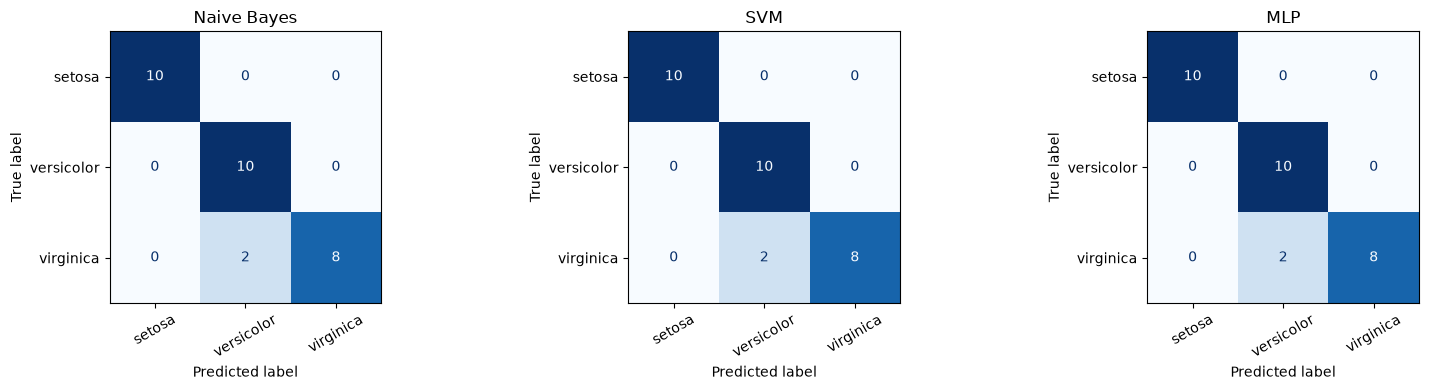

In [28]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

modelos_confusion = {
    "Naive Bayes": modelo_nb,
    "SVM": modelo_svm,
    "MLP": modelo_mlp
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (nombre, modelo) in zip(
    axes, modelos_confusion.items()
):
    ConfusionMatrixDisplay.from_estimator(
        modelo,
        X_test_scaled,
        Y_test,
        display_labels=iris.target_names,
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title(nombre)
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


### Errores de clasificación 

In [29]:

import numpy as np

# Predicciones de SVM
pred_svm = modelo_svm.predict(X_test_scaled)

# Identificar posiciones con errores
indices_error = np.where(pred_svm != Y_test)[0]

# Crear tabla con los ejemplos incorrectos
errores = pd.DataFrame(
    X_test[indices_error],
    columns=iris.feature_names
)

errores["Especie real"] = iris.target_names[
    Y_test[indices_error]
]

errores["Especie predicha"] = iris.target_names[
    pred_svm[indices_error]
]

display(errores.head(2))


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Especie real,Especie predicha
0,6.1,2.6,5.6,1.4,virginica,versicolor
1,6.3,2.8,5.1,1.5,virginica,versicolor


En los dos errores observamos que las flores *virginica* fueron clasificadas como *versicolor*. Esto podría deberse a la similitud de algunas medidas entre ambas especies, especialmente el ancho del pétalo. Sin embargo, no podemos asegurar la causa exacta solo con estos dos ejemplos.

### Tabla de resultados

In [30]:

# Información de las configuraciones utilizadas
configuraciones = {
    "Gaussian Naive Bayes": modelo_nb,
    "Regresión logística": modelo_lr,
    "Support Vector Machine": modelo_svm,
    "Arbol de decisión": modelo_dt,
    "Random Forest": modelo_rf,
    "Gradient Boosting": modelo_gb,
    "MLP": modelo_mlp
}

columnas_clave = {
    "Gaussian Naive Bayes": ["var_smoothing"],
    "Regresión logística": ["C", "max_iter"],
    "Support Vector Machine": ["kernel", "C"],
    "Arbol de decisión": ["max_depth"],
    "Random Forest": ["n_estimators", "max_depth"],
    "Gradient Boosting": ["n_estimators", "learning_rate"],
    "MLP": ["hidden_layer_sizes", "max_iter"]
}

filas = []

for nombre, modelo in configuraciones.items():
    parametros = modelo.get_params()

    resumen = ", ".join(
        f"{p}={parametros[p]}"
        for p in columnas_clave[nombre]
    )

    filas.append({
        "Modelo": nombre,
        "Transformación": "StandardScaler",
        "Hiperparámetros principales": resumen
    })

tabla_config = pd.DataFrame(filas)

tabla_final = pd.merge(
    tabla_config,
    tabla_prueba,
    on="Modelo"
)

display(tabla_final.round(4))


,Modelo,Transformación,Hiperparámetros principales,Accuracy prueba,F1 macro prueba
0,Gaussian Naive Bayes,StandardScaler,var_smoothing=1e-09,0.9333,0.9327
1,Regresión logística,StandardScaler,"C=1.0, max_iter=1000",0.9333,0.9327
2,Support Vector Machine,StandardScaler,"kernel=linear, C=1.0",0.9333,0.9327
3,Arbol de decisión,StandardScaler,max_depth=3,1.0000,1.0000
4,Random Forest,StandardScaler,"n_estimators=100, max_depth=None",0.9000,0.8977
5,Gradient Boosting,StandardScaler,"n_estimators=100, learning_rate=0.1",0.9333,0.9327
6,MLP,StandardScaler,"hidden_layer_sizes=(64, 32), max_iter=2000",0.9333,0.9327


### Preguntas de interpretación

1. **¿Cuál tuvo el mejor desempeño?**

El árbol de decisión, ya que obtuvo un Accuracy y un F1 macro de 1.0 en prueba. Esto no garantiza que siempre obtenga el mismo resultado con datos nuevos.

2. **¿Cuál fue el más sencillo de programar?**

Fue Naive Bayes, debido a que no necesitó tantos parámetros y su entrenamiento fue sencillo.

3. **¿Accuracy y F1 macro cuentan la misma historia?**

Se podría decir que sí, porque sus resultados fueron similares. Sin embargo, F1 macro nos permite examinar el rendimiento de cada clase dando el mismo peso a todas.

4. **¿Cuál es la diferencia entre macro y micro?**

Macro promedia la métrica de cada clase, dando el mismo peso a todas. Micro agrega las contribuciones de todas las clases antes de calcular la métrica. En este problema multiclase, F1 micro coincide con Accuracy.

5. **¿Qué aporta MLP frente a un modelo lineal?**

Permite aprender relaciones no lineales mediante capas ocultas, aunque en este experimento no superó al árbol de decisión en prueba.

# 3. Comparación de modelos de regresión

## Dataset: Diabetes


Carga Diabetes, incluido en scikit-learn.

Describe qué representa el objetivo numérico y qué variables contiene el dataset.

Comprueba en la descripción del dataset si las características ya incluyen transformaciones. No interpretes sus valores automáticamente como mediciones en unidades originales.

**Descripción del dataset:** El conjunto Diabetes contiene 442 pacientes y 10 características: edad, sexo, índice de masa corporal, presión arterial y seis medidas sanguíneas (s1 a s6). El objetivo es un valor numérico que representa una medida de progresión de la diabetes un año después. Las características incluidas por defecto ya fueron escaladas; por eso sus valores no deben interpretarse directamente como medidas originales.

In [31]:

from sklearn.datasets import load_diabetes
import pandas as pd

# Cargamos el dataset Diabetes
diabetes = load_diabetes()

# Separamos las características y el objetivo
X_reg = diabetes.data
y_reg = diabetes.target

# Mostramos la información básica
print("Dimensiones de X:", X_reg.shape)
print("Dimensiones de y:", y_reg.shape)

print("\nCaracterísticas:")
print(diabetes.feature_names)

print("\nDescripción del dataset:")
print(diabetes.DESCR)


Dimensiones de X: (442, 10)
Dimensiones de y: (442,)

Características:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

Descripción del dataset:
.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total chole

In [32]:
# Mostramos el nombre de las características
for nombre in diabetes.feature_names:
    print(nombre)

# Mostramos los primeros cinco valores objetivo
print("\nPrimeros cinco valores objetivo:")
print(y_reg[:5])

age
sex
bmi
bp
s1
s2
s3
s4
s5
s6

Primeros cinco valores objetivo:
[151.  75. 141. 206. 135.]


In [33]:

# Creamos una tabla con las características
df_diabetes = pd.DataFrame(
    X_reg,
    columns=diabetes.feature_names
)

# Agregamos el objetivo numérico
df_diabetes["objetivo"] = y_reg

# Mostramos cinco pacientes
display(df_diabetes.head(5))


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,objetivo
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


## Predicción inicial

¿Esperas que un modelo más flexible produzca siempre un menor error en datos nuevos? Justifica.

No necesariamente pues un modelo más flexible puede aprender relaciones más complejas, pero también puede ajustarse demasiado a los datos de entrenamiento. Por eso necesitamos comparar los modelos con validación y luego evaluarlos con datos de prueba.

## Modelos

Compara:

- Regresión lineal.
- Ridge.
- Lasso.
- kNN de regresión.
- Árbol de regresión.
- Random Forest de regresión.
- Gradient Boosting de regresión.
- MLP de regresión.

Usa escalamiento mediante pipelines cuando corresponda.

Si transformas el objetivo para facilitar el entrenamiento del MLP, ajusta esa transformación solo con entrenamiento y devuelve las predicciones a la escala original antes de evaluarlas.

## Procedimiento

Usa entrenamiento para ajustar y validación para decidir configuraciones. Una vez congeladas, evalúa los modelos sobre prueba.

Presenta:

| Modelo | MAE | RMSE | R² |
|---|---|---|---|

Para regresión lineal y MLP, incluye:

- Gráfico de valores reales frente a predicciones.
- Gráfico de residuos.
- Dos ejemplos con errores absolutos grandes.

## Regularización

Compara varias intensidades de penalización en Ridge y Lasso usando validación.

Examina:

- Magnitud de los coeficientes.
- Cantidad de coeficientes nulos en Lasso.
- Error de entrenamiento y validación.

## Interpretación

1. ¿Qué modelo tuvo el mejor desempeño?
2. ¿Por qué MAE y RMSE pueden favorecer resultados diferentes?
3. ¿Cómo se interpreta un R² negativo?
4. ¿Qué efecto tuvo aumentar la regularización?
5. ¿Qué puede explicar los errores grandes?
6. ¿Un coeficiente predictivo demuestra una relación causal?

In [34]:
# Dividir el dataset Diabetes

from sklearn.model_selection import train_test_split

# Primera división: 60% entrenamiento y 40% restante
X_train_reg, X_temp_reg, y_train_reg, y_temp_reg = train_test_split(
    X_reg, y_reg,
    test_size=0.4,
    random_state=42
)

# Segunda división: validación y prueba
X_val_reg, X_test_reg, y_val_reg, y_test_reg = train_test_split(
    X_temp_reg, y_temp_reg,
    test_size=0.5,
    random_state=42
)

print("Entrenamiento:", X_train_reg.shape)
print("Validación:", X_val_reg.shape)
print("Prueba:", X_test_reg.shape)


Entrenamiento: (265, 10)
Validación: (88, 10)
Prueba: (89, 10)


In [35]:
# Estandarizar las características

from sklearn.preprocessing import StandardScaler

# Creamos el estandarizador
scaler_reg = StandardScaler()

# Aprendemos la media y desviación del entrenamiento
X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)

# Aplicamos la misma transformación
X_val_reg_scaled = scaler_reg.transform(X_val_reg)
X_test_reg_scaled = scaler_reg.transform(X_test_reg)

print("Antes de estandarizar:")
print(X_train_reg[0])

print("\nDespués de estandarizar:")
print(X_train_reg_scaled[0])


Antes de estandarizar:
[-0.01277963 -0.04464164  0.06061839  0.05285804  0.04796534  0.02937467
 -0.01762938  0.03430886  0.07020738  0.00720652]

Después de estandarizar:
[-0.28515826 -0.92365949  1.2132367   1.09043158  0.97280402  0.61089613
 -0.38576886  0.71609684  1.44129926  0.11250343]


### Regresión Lineal

In [36]:
from sklearn.linear_model import LinearRegression

# Creamos el modelo
modelo_lineal = LinearRegression()

# Entrenamos con los 265 pacientes
modelo_lineal.fit(X_train_reg_scaled, y_train_reg)

# Realizamos predicciones sobre validación
y_pred_lineal = modelo_lineal.predict(X_val_reg_scaled)

print("Primeras 5 predicciones:")
print(y_pred_lineal[:5])

print("\nPrimeros 5 valores reales:")
print(y_val_reg[:5])

Primeras 5 predicciones:
[190.27106539 109.22980857  57.65781289  98.93581344  79.06215404]

Primeros 5 valores reales:
[233. 153.  63.  88.  37.]


In [37]:
# Evaluar el modelo

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Calculamos las métricas
mae_lineal = mean_absolute_error(
    y_val_reg, y_pred_lineal
)

rmse_lineal = np.sqrt(
    mean_squared_error(y_val_reg, y_pred_lineal)
)

r2_lineal = r2_score(
    y_val_reg, y_pred_lineal
)

print("MAE:", round(mae_lineal, 4))
print("RMSE:", round(rmse_lineal, 4))
print("R²:", round(r2_lineal, 4))


MAE: 38.2213
RMSE: 49.1497
R²: 0.581


### Ridge

In [38]:

from sklearn.linear_model import Ridge

# Creamos el modelo Ridge
modelo_ridge = Ridge(alpha=0.01)

# Entrenamos el modelo
modelo_ridge.fit(X_train_reg_scaled, y_train_reg)

# Realizamos predicciones en validación
y_pred_ridge = modelo_ridge.predict(X_val_reg_scaled)

print("Primeras 5 predicciones:")
print(y_pred_ridge[:5])

print("\nPrimeros 5 valores reales:")
print(y_val_reg[:5])


Primeras 5 predicciones:
[190.24966334 109.21840375  57.66822458  98.94297988  79.06128672]

Primeros 5 valores reales:
[233. 153.  63.  88.  37.]


In [39]:
# Evaluar Ridge
mae_ridge = mean_absolute_error(
    y_val_reg, y_pred_ridge
)

rmse_ridge = np.sqrt(
    mean_squared_error(y_val_reg, y_pred_ridge)
)

r2_ridge = r2_score(
    y_val_reg, y_pred_ridge
)

print("MAE:", round(mae_ridge, 4))
print("RMSE:", round(rmse_ridge, 4))
print("R²:", round(r2_ridge, 4))

MAE: 38.2222
RMSE: 49.1503
R²: 0.581


### Lasso

In [40]:
# Entrenar Lasso
from sklearn.linear_model import Lasso

# Creamos el modelo Lasso
modelo_lasso = Lasso(
    alpha=0.01,
    max_iter=10000
)

# Entrenamos el modelo
modelo_lasso.fit(X_train_reg_scaled, y_train_reg)

# Realizamos predicciones en validación
y_pred_lasso = modelo_lasso.predict(X_val_reg_scaled)

print("Primeras 5 predicciones:")
print(y_pred_lasso[:5])

print("\nPrimeros 5 valores reales:")
print(y_val_reg[:5])

Primeras 5 predicciones:
[189.92058485 109.07377814  57.73115861  99.01620799  79.01771361]

Primeros 5 valores reales:
[233. 153.  63.  88.  37.]


In [41]:
# Evaluar el modelo

# Calculamos las métricas de Lasso
mae_lasso = mean_absolute_error(
    y_val_reg, y_pred_lasso
)

rmse_lasso = np.sqrt(
    mean_squared_error(y_val_reg, y_pred_lasso)
)

r2_lasso = r2_score(
    y_val_reg, y_pred_lasso
)

print("MAE:", round(mae_lasso, 4))
print("RMSE:", round(rmse_lasso, 4))
print("R²:", round(r2_lasso, 4))


MAE: 38.2346
RMSE: 49.1575
R²: 0.5808


In [42]:

# Revisamos los coeficientes de Lasso
coeficientes = pd.DataFrame({
    "Característica": diabetes.feature_names,
    "Coeficiente": modelo_lasso.coef_
})

display(coeficientes.round(4))

# Contamos los coeficientes diferentes de cero
print("Características utilizadas:",
      np.count_nonzero(modelo_lasso.coef_))

print("Características descartadas:",
      np.sum(modelo_lasso.coef_ == 0))


,Característica,Coeficiente
0,age,0.8649
1,sex,-10.7581
2,bmi,28.3799
3,bp,17.3379
4,s1,-30.1126
5,s2,15.8269
6,s3,0.0037
7,s4,6.5454
8,s5,27.8173
9,s6,1.4839


Características utilizadas: 10
Características descartadas: 0


### kNN de regresión

In [43]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline

# kNN usa distancias, por eso incluimos el escalamiento en el pipeline
valores_k = [3, 5, 7, 9]
filas_knn = []
for k in valores_k:
    candidato = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))
    candidato.fit(X_train_reg, y_train_reg)
    pred = candidato.predict(X_val_reg)
    filas_knn.append([k, mean_absolute_error(y_val_reg, pred),
                      np.sqrt(mean_squared_error(y_val_reg, pred)),
                      r2_score(y_val_reg, pred)])
tabla_knn = pd.DataFrame(filas_knn, columns=['k', 'MAE', 'RMSE', 'R²'])
display(tabla_knn.round(4))
mejor_k = int(tabla_knn.loc[tabla_knn['RMSE'].idxmin(), 'k'])
modelo_knn_reg = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=mejor_k))
modelo_knn_reg.fit(X_train_reg, y_train_reg)
y_pred_knn = modelo_knn_reg.predict(X_val_reg)
mae_knn = mean_absolute_error(y_val_reg, y_pred_knn)
rmse_knn = np.sqrt(mean_squared_error(y_val_reg, y_pred_knn))
r2_knn = r2_score(y_val_reg, y_pred_knn)
print('Mejor k:', mejor_k)
print('MAE:', round(mae_knn, 4), 'RMSE:', round(rmse_knn, 4), 'R²:', round(r2_knn, 4))


,k,MAE,RMSE,R²
0,3,42.5720,56.7871,0.4406
1,5,45.4523,57.7070,0.4224
2,7,45.1672,56.6330,0.4437
3,9,44.7348,54.6748,0.4815


Mejor k: 9
MAE: 44.7348 RMSE: 54.6748 R²: 0.4815


### Árbol de regresión

In [44]:
# Entrenar el modelo

from sklearn.tree import DecisionTreeRegressor

# Creamos el modelo

modelo_arbol_reg = DecisionTreeRegressor(
    max_depth=2,
    random_state=42
)

# Entrenamos el modelo
modelo_arbol_reg.fit(X_train_reg_scaled, y_train_reg)

# Realizamos predicciones de validación
y_pred_arbol_reg = modelo_arbol_reg.predict(X_val_reg_scaled)

print("Primeras 5 predicciones:")
print(y_pred_arbol_reg[:5])

print("\nPrimeros 5 valores reales:")
print(y_val_reg[:5])

Primeras 5 predicciones:
[149.61666667  99.41904762  99.41904762  99.41904762  99.41904762]

Primeros 5 valores reales:
[233. 153.  63.  88.  37.]


In [45]:
# Evaluar el árbol

# Calculamos las métricas
mae_arbol = mean_absolute_error(
    y_val_reg, y_pred_arbol_reg
)

rmse_arbol = np.sqrt(
    mean_squared_error(y_val_reg, y_pred_arbol_reg)
)

r2_arbol = r2_score(
    y_val_reg, y_pred_arbol_reg
)

print("MAE:", round(mae_arbol, 4))
print("RMSE:", round(rmse_arbol, 4))
print("R²:", round(r2_arbol, 4))


MAE: 44.8429
RMSE: 56.3482
R²: 0.4492


### Random Forest Regressor

In [46]:
# Entrenar el modelo

from sklearn.ensemble import RandomForestRegressor

# Creamos un bosque de 100 árboles
modelo_rf_reg = RandomForestRegressor(
    n_estimators=100,
    max_depth=3,
    random_state=42
)

# Entrenamos el modelo
modelo_rf_reg.fit(X_train_reg_scaled, y_train_reg)

# Realizamos predicciones de validación
y_pred_rf_reg = modelo_rf_reg.predict(X_val_reg_scaled)

print("Primeras 5 predicciones:")
print(y_pred_rf_reg[:5])

print("\nPrimeros 5 valores reales:")
print(y_val_reg[:5])


Primeras 5 predicciones:
[158.66866745 105.89024908  90.31388915  99.33310354  90.20908085]

Primeros 5 valores reales:
[233. 153.  63.  88.  37.]


In [47]:
# Evaluar el modelo

# Calculamos las métricas
mae_rf_reg = mean_absolute_error(
    y_val_reg, y_pred_rf_reg
)

rmse_rf_reg = np.sqrt(
    mean_squared_error(y_val_reg, y_pred_rf_reg)
)

r2_rf_reg = r2_score(
    y_val_reg, y_pred_rf_reg
)

print("MAE:", round(mae_rf_reg, 4))
print("RMSE:", round(rmse_rf_reg, 4))
print("R²:", round(r2_rf_reg, 4))


MAE: 41.1043
RMSE: 51.8182
R²: 0.5342


### Gradient Boosting Regressor

In [48]:
from sklearn.ensemble import GradientBoostingRegressor

# Creamos el modelo

modelo_gb_reg = GradientBoostingRegressor(
    n_estimators=50,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Entrenamos el modelo
modelo_gb_reg.fit(X_train_reg_scaled, y_train_reg)

# Realizamos predicciones de validación
y_pred_gb_reg = modelo_gb_reg.predict(X_val_reg_scaled)

print("Primeras 5 predicciones:")
print(y_pred_gb_reg[:5])

print("\nPrimeros 5 valores reales:")
print(y_val_reg[:5])


Primeras 5 predicciones:
[168.07768972  79.86226158  75.78268174 104.1606663   83.64101564]

Primeros 5 valores reales:
[233. 153.  63.  88.  37.]


In [49]:
# Evaluamos el modelo


# Calculamos las métricas
mae_gb_reg = mean_absolute_error(
    y_val_reg, y_pred_gb_reg
)

rmse_gb_reg = np.sqrt(
    mean_squared_error(y_val_reg, y_pred_gb_reg)
)

r2_gb_reg = r2_score(
    y_val_reg, y_pred_gb_reg
)

print("MAE:", round(mae_gb_reg, 4))
print("RMSE:", round(rmse_gb_reg, 4))
print("R²:", round(r2_gb_reg, 4))


MAE: 41.9322
RMSE: 52.2484
R²: 0.5265


### MLPRegressor

In [50]:
# Entrenar la red neuronal

from sklearn.neural_network import MLPRegressor

# Creamos la red neuronal para regresión
modelo_mlp_reg = MLPRegressor(
    hidden_layer_sizes=(32, 16),
    learning_rate_init=0.001,
    activation="relu",
    max_iter=2000,
    random_state=42
)

# Entrenamos el modelo
modelo_mlp_reg.fit(X_train_reg_scaled, y_train_reg)

# Realizamos predicciones de validación
y_pred_mlp_reg = modelo_mlp_reg.predict(X_val_reg_scaled)

print("Primeras 5 predicciones:")
print(y_pred_mlp_reg[:5])

print("\nPrimeros 5 valores reales:")
print(y_val_reg[:5])


Primeras 5 predicciones:
[193.03257233  96.39329838  58.17426419 122.4742886   84.14456275]

Primeros 5 valores reales:
[233. 153.  63.  88.  37.]


c:\Users\HANDRESTH\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (2000) reached and the optimization hasn't converged yet.
  warnings.warn(


In [51]:
# Evaluar el modelo

# Calculamos las métricas del MLP
mae_mlp_reg = mean_absolute_error(
    y_val_reg, y_pred_mlp_reg
)

rmse_mlp_reg = np.sqrt(
    mean_squared_error(y_val_reg, y_pred_mlp_reg)
)

r2_mlp_reg = r2_score(
    y_val_reg, y_pred_mlp_reg
)

print("MAE:", round(mae_mlp_reg, 4))
print("RMSE:", round(rmse_mlp_reg, 4))
print("R²:", round(r2_mlp_reg, 4))


MAE: 39.3896
RMSE: 51.513
R²: 0.5397


### Tabla comparativa


In [52]:

resultados_reg = pd.DataFrame({
    "Modelo": [
        "Regresión lineal",
        "Ridge", "Lasso", 
        "kNN de regresión",
        "Árbol de regresión",
        "Random Forest",
        "Gradient Boosting",
        "MLP"
    ],
    "MAE validación": [
        mae_lineal,
        mae_ridge,
        mae_lasso,
        mae_knn,
        mae_arbol,
        mae_rf_reg,
        mae_gb_reg,
        mae_mlp_reg
    ],
    "RMSE validación": [
        rmse_lineal,
        rmse_ridge,
        rmse_lasso,
        rmse_knn,
        rmse_arbol,
        rmse_rf_reg,
        rmse_gb_reg,
        rmse_mlp_reg
    ],
    "R² validación": [
        r2_lineal,
        r2_ridge,
        r2_lasso,
        r2_knn,
        r2_arbol,
        r2_rf_reg,
        r2_gb_reg,
        r2_mlp_reg
    ]
})

display(resultados_reg.round(4))


,Modelo,MAE validación,RMSE validación,R² validación
0,Regresión lineal,38.2213,49.1497,0.5810
1,Ridge,38.2222,49.1503,0.5810
2,Lasso,38.2346,49.1575,0.5808
3,kNN de regresión,44.7348,54.6748,0.4815
4,Árbol de regresión,44.8429,56.3482,0.4492
5,Random Forest,41.1043,51.8182,0.5342
6,Gradient Boosting,41.9322,52.2484,0.5265
7,MLP,39.3896,51.5130,0.5397


### Comparación de regularización

Se va a comparar los coeficientes y el error de entrenamiento y validación de Ridge y Lasso, utilizando solamente entrenamiento y validación, sin consultar el conjunto de prueba.

In [53]:
# Comparación solicitada de distintas intensidades de regularización
filas_regularizacion = []
for tipo, clase in [('Ridge', Ridge), ('Lasso', Lasso)]:
    for alpha in [0.01, 0.1, 1, 10]:
        candidato = clase(alpha=alpha, max_iter=10000) if tipo == 'Lasso' else clase(alpha=alpha)
        candidato.fit(X_train_reg_scaled, y_train_reg)
        pred_ent = candidato.predict(X_train_reg_scaled)
        pred_val = candidato.predict(X_val_reg_scaled)
        filas_regularizacion.append({
            'Modelo': tipo, 'Alpha': alpha,
            'RMSE entrenamiento': np.sqrt(mean_squared_error(y_train_reg, pred_ent)),
            'RMSE validación': np.sqrt(mean_squared_error(y_val_reg, pred_val)),
            'Magnitud de coeficientes': np.linalg.norm(candidato.coef_),
            'Coeficientes nulos': int(np.sum(candidato.coef_ == 0))
        })
tabla_regularizacion = pd.DataFrame(filas_regularizacion)
display(tabla_regularizacion.round(4))


,Modelo,Alpha,RMSE entrenamiento,RMSE validación,Magnitud de coeficientes,Coeficientes nulos
0,Ridge,0.01,54.2849,49.1503,57.8468,0
1,Ridge,0.10,54.2851,49.1556,56.8925,0
2,Ridge,1.00,54.2966,49.2033,50.5723,0
3,Ridge,10.00,54.3951,49.3731,41.0899,0
4,Lasso,0.01,54.2853,49.1575,56.5562,0
5,Lasso,0.10,54.3023,49.2036,49.2629,0
6,Lasso,1.00,54.4733,49.5254,41.0947,2
7,Lasso,10.00,57.3864,53.8209,30.8192,6


### Evaluación final en prueba

Los hiperparámetros anteriores ya se eligieron usando validación. Ejecuta la siguiente celda solo una vez para obtener las métricas finales de prueba; no modifiques configuraciones a partir de estos resultados.

In [54]:
# Reunimos los modelos que ya fueron entrenados
modelos_reg = {
    'Regresión lineal': modelo_lineal,
    'Ridge': modelo_ridge,
    'Lasso': modelo_lasso,
    'kNN de regresión': modelo_knn_reg,
    'Árbol de regresión': modelo_arbol_reg,
    'Random Forest': modelo_rf_reg,
    'Gradient Boosting': modelo_gb_reg,
    'MLP': modelo_mlp_reg
}
filas_prueba = []
for nombre, modelo in modelos_reg.items():
    # kNN recibe datos sin estandarizar: su pipeline realiza la transformación
    datos = X_test_reg if nombre == 'kNN de regresión' else X_test_reg_scaled
    pred = modelo.predict(datos)
    filas_prueba.append([nombre, mean_absolute_error(y_test_reg, pred),
                        np.sqrt(mean_squared_error(y_test_reg, pred)),
                        r2_score(y_test_reg, pred)])
tabla_prueba_reg = pd.DataFrame(filas_prueba, columns=['Modelo', 'MAE', 'RMSE', 'R²'])
display(tabla_prueba_reg.round(4))


,Modelo,MAE,RMSE,R²
0,Regresión lineal,46.7240,56.9703,0.4389
1,Ridge,46.7250,56.9718,0.4389
2,Lasso,46.7404,56.9918,0.4385
3,kNN de regresión,47.5630,58.2817,0.4128
4,Árbol de regresión,50.4491,63.5908,0.3009
5,Random Forest,46.7475,57.0178,0.4380
6,Gradient Boosting,45.0732,55.6839,0.4640
7,MLP,43.7006,54.4329,0.4878


### Gráficos y errores de regresión

Gráficos reales frente a predicciones y de residuos para regresión lineal y MLP, además de dos ejemplos con errores absolutos grandes.

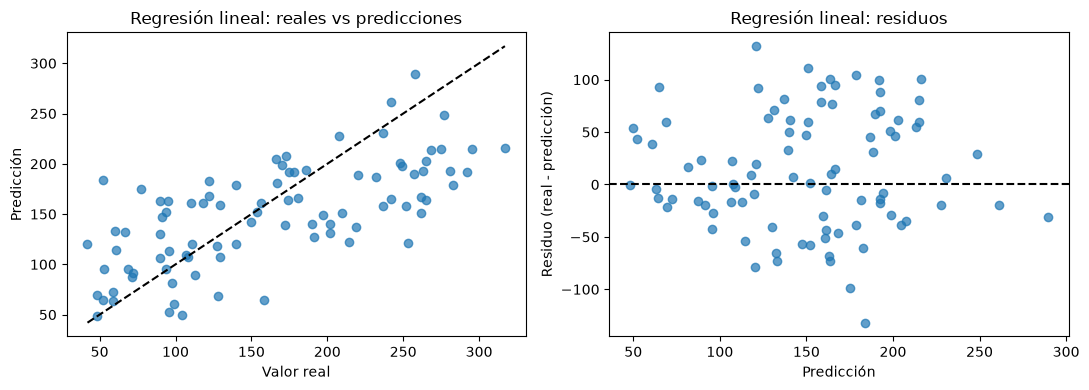

Dos errores grandes de Regresión lineal


,Índice en prueba,Valor real,Predicción,Error absoluto
0,39,253.0,121.029,131.971
1,8,52.0,183.811,131.811


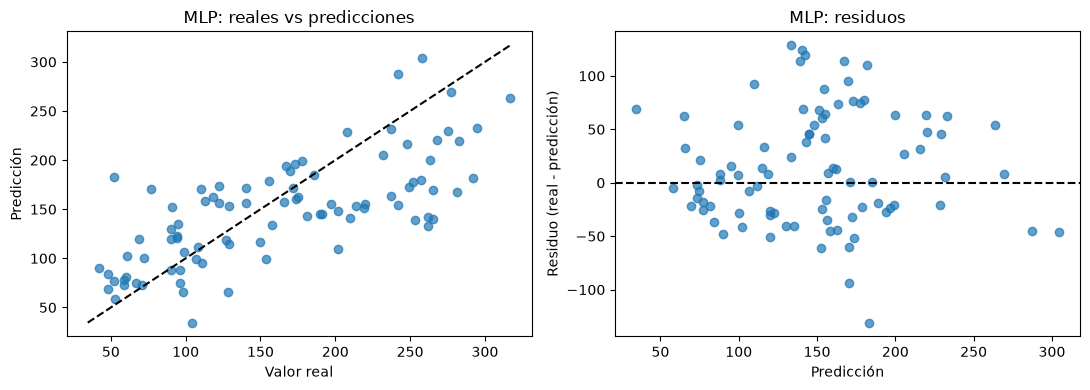

Dos errores grandes de MLP


,Índice en prueba,Valor real,Predicción,Error absoluto
0,8,52.0,182.871,130.871
1,87,262.0,133.295,128.705


In [55]:
# Gráficos solicitados para regresión lineal y MLP
for nombre, modelo in [('Regresión lineal', modelo_lineal), ('MLP', modelo_mlp_reg)]:
    pred = modelo.predict(X_test_reg_scaled)
    residuos = y_test_reg - pred
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].scatter(y_test_reg, pred, alpha=0.7)
    inferior = min(y_test_reg.min(), pred.min())
    superior = max(y_test_reg.max(), pred.max())
    axes[0].plot([inferior, superior], [inferior, superior], 'k--')
    axes[0].set(xlabel='Valor real', ylabel='Predicción', title=f'{nombre}: reales vs predicciones')
    axes[1].scatter(pred, residuos, alpha=0.7)
    axes[1].axhline(0, color='black', linestyle='--')
    axes[1].set(xlabel='Predicción', ylabel='Residuo (real - predicción)', title=f'{nombre}: residuos')
    plt.tight_layout()
    plt.show()

    # Dos ejemplos de mayor error absoluto para cada modelo
    indices = np.argsort(np.abs(residuos))[-2:][::-1]
    ejemplos = pd.DataFrame({
        'Índice en prueba': indices,
        'Valor real': y_test_reg[indices],
        'Predicción': pred[indices],
        'Error absoluto': np.abs(residuos[indices])
    })
    print('Dos errores grandes de', nombre)
    display(ejemplos.round(3))


### Preguntas de interpretación de regresión

1. **¿Qué modelo tuvo el mejor desempeño?**

En el conjunto de prueba fue MLP, con MAE de 43.7006, RMSE de 54.4329 y R² de 0.4878. Aunque en validación la regresión lineal obtuvo mejores resultados, en prueba MLP consiguió el menor error.

2. **¿Por qué MAE y RMSE pueden favorecer resultados diferentes?**

Porque MAE calcula el promedio de los errores absolutos, mientras que RMSE penaliza más los errores grandes. Por eso dos modelos pueden tener un orden diferente dependiendo de la métrica.

3. **¿Cómo se interpreta un R² negativo?**

Significa que el modelo predice peor que utilizar el promedio de los valores reales del conjunto evaluado.

4. **¿Qué efecto tuvo aumentar la regularización?**

Al aumentar alpha, los coeficientes de Ridge y Lasso redujeron su magnitud. En Lasso, con alpha=1 se anularon dos coeficientes y con alpha=10 fueron seis. Además, los errores de entrenamiento y validación aumentaron en los valores que probamos. El mejor RMSE de validación de ambos modelos fue con alpha=0.01.

5. **¿Qué puede explicar los errores grandes?**

Algunos pacientes pueden tener valores que el modelo no consigue representar bien. En regresión lineal, por ejemplo, un valor real de 253 fue predicho como 121.029, y en MLP un valor real de 52 fue predicho como 182.871. Estos errores muestran las limitaciones de los modelos, pero no permiten conocer la causa exacta.

6. **¿Un coeficiente predictivo demuestra una relación causal?**

No, ya que un coeficiente puede indicar una relación que ayuda a predecir, pero no demuestra que una característica sea la causa de la progresión de la enfermedad.
